<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/abandon_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Rotación de clientes de telecomunicaciones**
https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data

### **Contexto**

Prediga el comportamiento para fidelizar a sus clientes. Puede analizar todos los datos relevantes de los clientes y desarrollar programas de retención de clientes específicos." [Conjuntos de datos de muestra de IBM]

Contenido
Cada fila representa a un cliente, y cada columna contiene los atributos del cliente descritos en la columna Metadatos.

Los datos brutos contienen 7043 filas (clientes) y 21 columnas (características).

La columna **"Churn"** es nuestro objetivo.

**Estructura del notebook (flujo ETL)**

0. **Configuración**: Importación de librerías.
1. **Extracción (E)**: Descarga y lectura del dataset desde Kaggle.
2. **Transformación (T)**: Perfilado, limpieza, estandarización, división y clasificación de variables.
3. **Análisis exploratorio (EDA)**: Distribución de cada variable y su relación con el abandono.
4. **Pipelines y modelado**: Preprocesamiento con **ColumnTransformer** y entrenamiento del modelo sin fuga de información.
5. **Carga (L)**: Guardado del modelo entrenado, instrucciones de uso y descarga.

## **0. Configuración del entorno**

### **0.1 Importación de librerías**

In [1]:
import kagglehub
import os
import joblib
import sklearn
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
import numpy as np
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import chi2_contingency
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import math
import matplotlib.pyplot as plt

## **1. Extracción (E)**

Obtención de los datos crudos desde la fuente original (Kaggle).

### **1.1 Descarga y lectura del dataset**

In [2]:
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)
file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


### 1.2 Vista preliminar de los datos crudos

In [3]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


## **2. Transformación (T)**

Perfilado de calidad, limpieza, estandarización y preparación de los datos.

### **2.1 Perfilado: estructura y tipos de datos**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### **2.2 Perfilado: valores nulos, duplicados y espacios en blanco**

In [5]:
valores_nulos = df.isnull().sum()
valores_duplicados = df.duplicated().sum()
print("Valores nulos, duplicados\n")
print(f"Valores nulos: {valores_nulos}\n")
print(f"Valores duplicados {valores_duplicados}")

Valores nulos, duplicados

Valores nulos: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Valores duplicados 0


In [7]:
def es_celda_vacia(columna):
    return columna.str.strip() == ''

espacios_en_blanco = df.astype(str).apply(es_celda_vacia).sum()

print("Conteo de valores en blanco por columna:\n", espacios_en_blanco[espacios_en_blanco > 0])

Conteo de valores en blanco por columna:
 TotalCharges    11
dtype: int64


### **2.3 Limpieza: conversión de *TotalCharges* a tipo numérico**

In [8]:
# Convertimos a numérico: los espacios en blanco pasan a NaN

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Verificamos si se filtro nulos en el proceso

print("Valores nulos en TotalCharges tras la conversión:", df['TotalCharges'].isnull().sum())

# Resumen
df.info()


Valores nulos en TotalCharges tras la conversión: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   ob

### **2.4 Perfilado: estadística descriptiva**

#### Todas las variables

In [12]:
estadisticos = df.describe(include="all").T
estadisticos

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Variables numéricas

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### **2.5 Estandarización: traducción de nombres de variables al español**

In [13]:
traduccion_variables = {
    'customerID': 'ID_Cliente',
    'gender': 'Genero',
    'SeniorCitizen': 'Adulto_Mayor',
    'Partner': 'Tiene_Pareja',
    'Dependents': 'Tiene_Dependientes',
    'tenure': 'Meses_Permanencia',
    'PhoneService': 'Servicio_Telefonico',
    'MultipleLines': 'Lineas_Multiples',
    'InternetService': 'Servicio_Internet',
    'OnlineSecurity': 'Seguridad_Online',
    'OnlineBackup': 'Respaldo_Online',
    'DeviceProtection': 'Proteccion_Dispositivo',
    'TechSupport': 'Soporte_Tecnico',
    'StreamingTV': 'Transmision_TV',
    'StreamingMovies': 'Transmision_Peliculas',
    'Contract': 'Tipo_Contrato',
    'PaperlessBilling': 'Facturacion_Sin_Papel',
    'PaymentMethod': 'Metodo_Pago',
    'MonthlyCharges': 'Cargos_Mensuales',
    'TotalCharges': 'Cargos_Totales',
    'Churn': 'Abandono_Cliente'
}
df = df.rename(columns=traduccion_variables)

### **2.6 Estandarización: diccionario de variables**

> **Variable Objetivo**
> *   **Abandono_Cliente (Variable Objetivo):** Indica si el cliente canceló su servicio y dejó la compañía (Yes) o si continúa activo (No).
>
> **Variables Demográficas**
> *   **Genero (Variable Nominal):** Identifica si el cliente es hombre (Male) o mujer (Female).
> *   **Adulto_Mayor (Variable Numérica / Binaria):** Indica si el cliente es una persona de la tercera edad (1) o no (0).
> *   **Tiene_Pareja (Variable Nominal):** Indica si el cliente tiene un compañero sentimental (Yes / No).
> *   **Tiene_Dependientes (Variable Nominal):** Indica si el cliente tiene personas a su cargo, como hijos o familiares (Yes / No).
>
> **Servicios Contratados**
> *   **Servicio_Telefonico (Variable Nominal):** Indica si el cliente tiene contratado el servicio de telefonía fija (Yes / No).
> *   **Lineas_Multiples (Variable Nominal):** Especifica si el cliente tiene una, varias líneas telefónicas o si no cuenta con servicio telefónico.
> *   **Servicio_Internet (Variable Nominal):** Tipo de conexión de internet del cliente (DSL, Fiber optic o No).
> *   **Seguridad_Online (Variable Nominal):** Indica si tiene contratado el servicio de seguridad adicional para internet.
> *   **Respaldo_Online (Variable Nominal):** Indica si cuenta con un servicio de copia de seguridad en la nube.
> *   **Proteccion_Dispositivo (Variable Nominal):** Indica si el cliente tiene un plan de protección o seguro para sus equipos electrónicos.
> *   **Soporte_Tecnico (Variable Nominal):** Indica si tiene contratado asistencia técnica prioritaria con la compañía.
> *   **Transmision_TV (Variable Nominal):** Indica si utiliza la conexión de internet para ver televisión por streaming.
> *   **Transmision_Peliculas (Variable Nominal):** Indica si utiliza el servicio de internet para ver películas por streaming.
>
> **Información de la Cuenta y Facturación**
> *   **Meses_Permanencia (Variable Numérica Continua):** Cantidad de meses que el cliente ha estado contratando los servicios de la empresa.
> *   **Tipo_Contrato (Variable Ordinal):** Frecuencia de renovación del contrato (Mes a mes, un año, dos años).
> *   **Facturacion_Sin_Papel (Variable Nominal):** Indica si el cliente prefiere recibir su factura de manera digital en lugar de impresa (Yes / No).
> *   **Metodo_Pago (Variable Nominal):** Forma en la que el cliente paga su factura (Cheque electrónico, cheque enviado por correo, transferencia bancaria o tarjeta de crédito).
> *   **Cargos_Mensuales (Variable Numérica Continua):** El monto total que se le cobra al cliente mensualmente por los servicios.
> *   **Cargos_Totales (Variable Numérica Continua):** La cantidad acumulada de dinero que el cliente ha pagado a lo largo de todo su tiempo en la compañía.

### **2.7 División del conjunto de datos (entrenamiento 80% / prueba 20%) y variable objetivo**

In [14]:
datos = df.copy()
y = None
X = None

# Separamos las variables x,y
if "Abandono_Cliente" in datos.columns:
    y = datos["Abandono_Cliente"]
    X = datos.drop(columns=["Abandono_Cliente", 'ID_Cliente'])


# Dividir el conjunto de datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

Tamaño de X_train: (5634, 19)
Tamaño de X_test: (1409, 19)


### **2.8 Clasificación de variables por tipo (numéricas, nominales y ordinales)**

In [15]:
#Definimos que orden deben tener las ordinales
orden_ordinales = {
    'Tipo_Contrato': ['Month-to-month', 'One year', 'Two year']
}

numericas_reales = [
    col for col in X_train.columns
    if col in ['Adulto_Mayor', 'Meses_Permanencia', 'Cargos_Mensuales', 'Cargos_Totales']
]

ordinales = [
    col for col in orden_ordinales.keys()
    if col in X_train.columns
]


nominales = [
    col for col in X_train.columns
    if col not in numericas_reales and col not in ordinales and col != 'ID_Cliente'
]

print("\nVariables Numéricas:", numericas_reales)
print("\nVariables Categóricas Nominales:", nominales)
print("\nVariables Categóricas Ordinales:", ordinales)


Variables Numéricas: ['Adulto_Mayor', 'Meses_Permanencia', 'Cargos_Mensuales', 'Cargos_Totales']

Variables Categóricas Nominales: ['Genero', 'Tiene_Pareja', 'Tiene_Dependientes', 'Servicio_Telefonico', 'Lineas_Multiples', 'Servicio_Internet', 'Seguridad_Online', 'Respaldo_Online', 'Proteccion_Dispositivo', 'Soporte_Tecnico', 'Transmision_TV', 'Transmision_Peliculas', 'Facturacion_Sin_Papel', 'Metodo_Pago']

Variables Categóricas Ordinales: ['Tipo_Contrato']


## **3. Análisis Exploratorio de Datos (EDA)**

Realizamos la tarea únicamente sobre el conjunto de entrenamiento para evitar fuga de información (**data leakage**).

### 3.0 Colores de las gráficas

In [17]:
# Aqui definimos el color a usar en las graficas

color_no = '#2a78d6'   # azul: el cliente se queda (No)
color_si = '#eb6834'   # naranja: el cliente abandona (Yes)
color_general = 'steelblue'

### **3.1 Distribución de la variable objetivo (balance de clases)**

Se compara la proporción de **Abandono_Cliente** en el dataset completo, en entrenamiento y en prueba para medir el desbalance y comprobar que la división estratificada conservó las proporciones.

Abandono_Cliente
No     5174
Yes    1869
Name: count, dtype: int64
Abandono_Cliente
No     73.5
Yes    26.5
Name: proportion, dtype: float64

% de abandono en entrenamiento: 26.5
% de abandono en prueba: 26.5


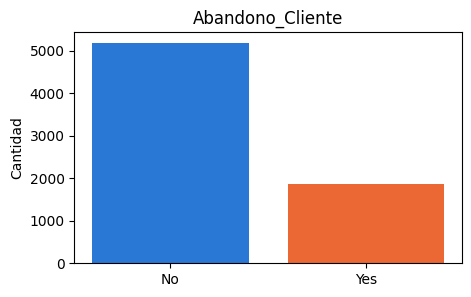

In [18]:
# Contamos y calculamos el porcentaje de clientes que se quedan (No) y que abandonan (Yes)

conteo = df['Abandono_Cliente'].value_counts()
print(conteo)
print((df['Abandono_Cliente'].value_counts(normalize=True) * 100).round(1))

# Comprobamos que entrenamiento y prueba conservan la misma proporción
print()
print('% de abandono en entrenamiento:', round((y_train == 'Yes').mean() * 100, 1))
print('% de abandono en prueba:', round((y_test == 'Yes').mean() * 100, 1))

plt.figure(figsize=(5, 3))
plt.bar(conteo.index, conteo.values, color=[color_no, color_si])
plt.title('Abandono_Cliente')
plt.ylabel('Cantidad')
plt.show()

**Hallazgos: balance de la objetivo**
- La clase está **desbalanceada**: en un 73.5% **No** frente a 26.5% **Yes**
- La división estratificada conservó exactamente la misma proporción en entrenamiento y prueba.
- Implicación para el modelado: usar **class_weight='balanced'** o remuestreo, y evaluar con recall, F1 y ROC-AUC en lugar de solo accuracy (un modelo que siempre prediga **No** ya obtendría aprox. 73.5% de accuracy).

### **3.2 Distribución de las variables numéricas (sesgo y valores atípicos)**

- **Asimetría**: cerca de 0 = simétrica; mayor a 0.5 = sesgo a la derecha; menor a -0.5 = sesgo a la izquierda.
- **Valores atípicos**: datos que quedan muy lejos del resto (regla del rango intercuartílico, IQR).
- **Adulto_Mayor** solo toma los valores 0 y 1, por eso se analiza con las categóricas.

In [20]:
# Resumimos a cada variable numérica: media, mediana, sesgo y valores atípicos

variables_continuas = ['Meses_Permanencia', 'Cargos_Mensuales', 'Cargos_Totales']

resumen = []
for var in variables_continuas:
    datos = X_train[var].dropna()   #Si hay alguna celda en X_train[var] la eliminamos
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1
    atipicos = datos[(datos < q1 - 1.5 * iqr) | (datos > q3 + 1.5 * iqr)]

    resumen.append({
        'Variable': var,
        'Nulos': X_train[var].isna().sum(),
        'Media': datos.mean(),
        'Mediana': datos.median(),
        'Asimetría': datos.skew(),
        'Valores atípicos': len(atipicos),
    })

tabla_numericas = pd.DataFrame(resumen).round(2)
tabla_numericas

,Variable,Nulos,Media,Mediana,Asimetría,Valores atípicos
0,Meses_Permanencia,0,32.49,29.00,0.24,0
1,Cargos_Mensuales,0,64.93,70.50,-0.22,0
2,Cargos_Totales,8,2302.60,1398.12,0.95,0


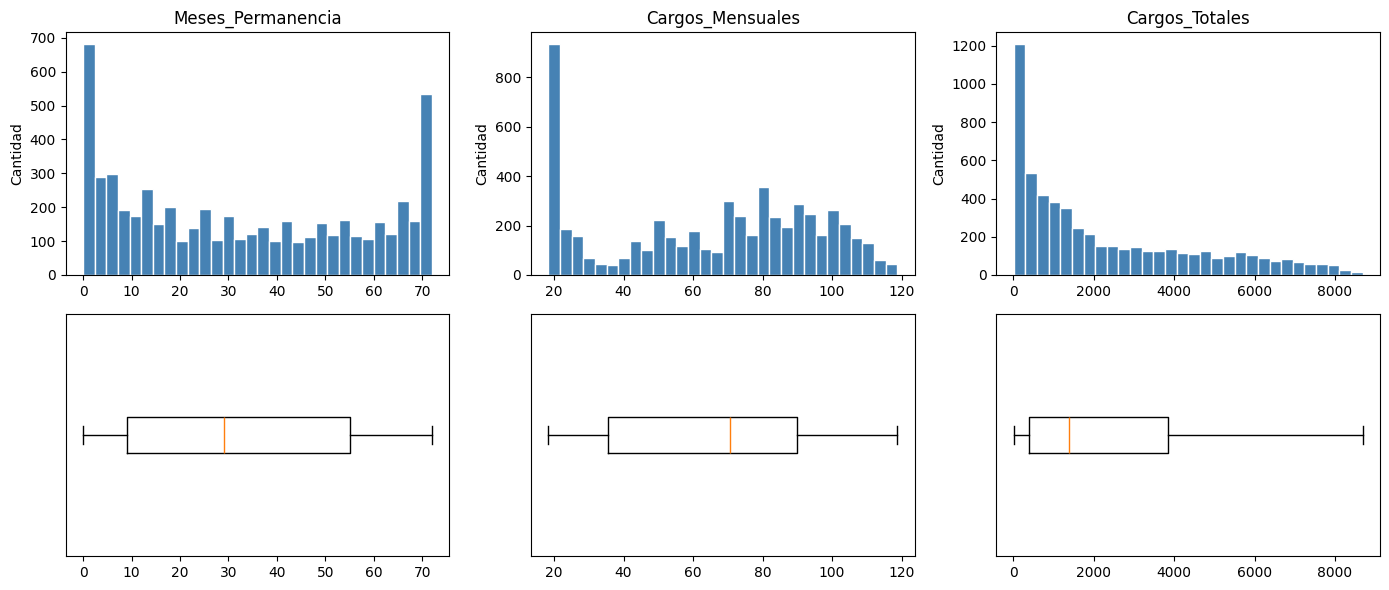

In [22]:
# Visualizacion de las distribuciones de las variables predictoras

plt.figure(figsize=(14, 6))

for i, var in enumerate(variables_continuas):
    datos = X_train[var].dropna()

    plt.subplot(2, 3, i + 1)
    plt.hist(datos, bins=30, color=color_general, edgecolor='white')
    plt.title(var)
    plt.ylabel('Cantidad')

    plt.subplot(2, 3, i + 4)
    plt.boxplot(datos, vert=False)
    plt.yticks([])

plt.tight_layout()
plt.show()

**Hallazgos: variables numéricas**
- **Meses_Permanencia** (asimetría 0.24) y **Cargos_Mensuales** (-0.22) son casi simétricas, pero tienen **dos picos**: muchos clientes nuevos (0 a 2 meses) y muchos antiguos (aprox. 72 meses); muchos planes básicos (aprox. 20 USD) y muchos planes caros.
- **Cargos_Totales** tiene **sesgo a la derecha** (asimetría 0.95; media 2302.6 > mediana 1398.1) y 8 valores nulos en entrenamiento.
- **No hay valores atípicos** en ninguna variable numérica, así que no es necesario eliminar datos.

### **3.3 Distribución de las variables categóricas (frecuencias y categorías minoritarias)**

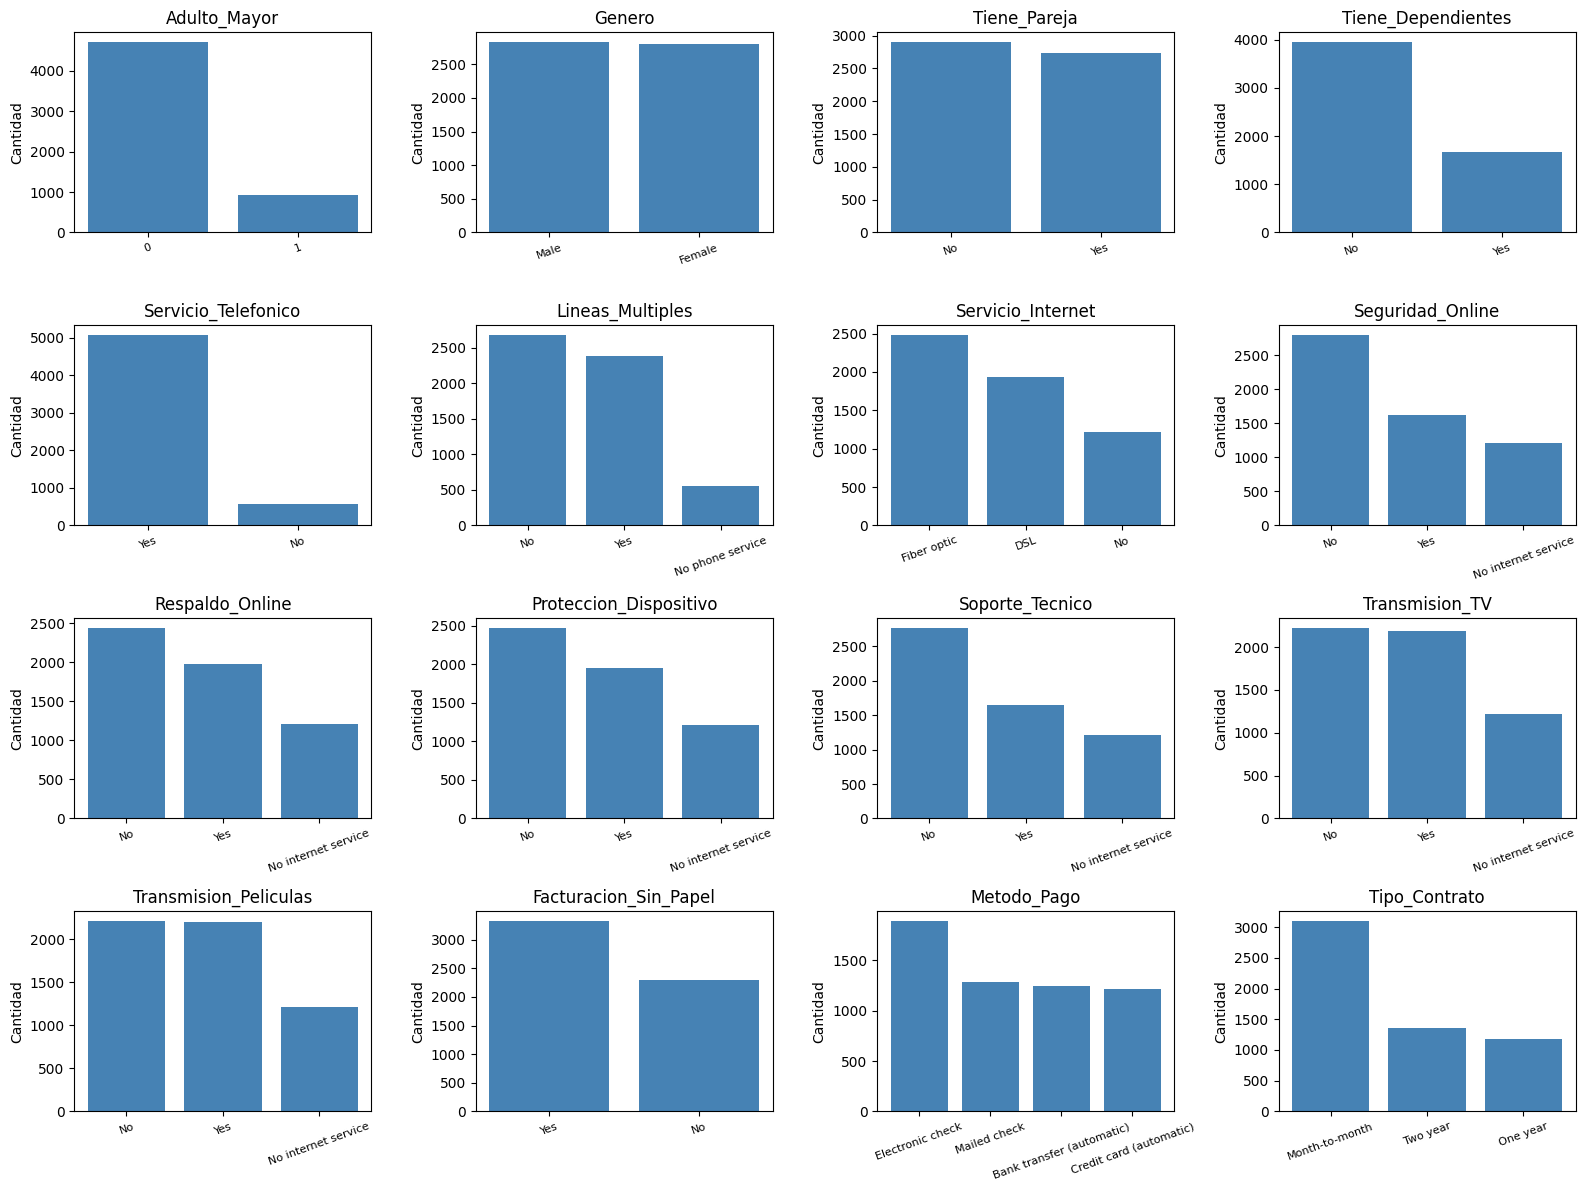

In [23]:
# Distribuciones de las variables categoricas
categoricas_distribucion = ['Adulto_Mayor'] + nominales + ordinales

plt.figure(figsize=(16, 12))

for i, var in enumerate(categoricas_distribucion):
    conteo = X_train[var].value_counts()

    plt.subplot(4, 4, i + 1)
    plt.bar(conteo.index.astype(str), conteo.values, color=color_general)
    plt.title(var)
    plt.ylabel('Cantidad')
    plt.xticks(rotation=20, fontsize=8)

plt.tight_layout()
plt.show()

**Hallazgos: variables categóricas**
- **Servicio_Telefonico** está muy concentrada (90.1% **Yes**) y **Adulto_Mayor** también (83.7% **No**), por lo que aportan poca variabilidad.
- **Genero** y **Tiene_Pareja** están prácticamente equilibradas (aprox. 50/50).
- La categoría **No internet service** (21.5%) se repite en 6 variables de servicios y **No phone service** (9.9%) en **Lineas_Multiples**: es información **redundante** con **Servicio_Internet** y **Servicio_Telefonico**.
- **Tipo_Contrato** está dominada por contratos mes a mes (55.1%).

### **3.4 Relación de las variables numéricas con el abandono**

- **Pearson** y **Spearman** van de -1 a 1. Un valor negativo indica que, a mayor valor de la variable, **menos** abandono; uno positivo, **más** abandono. Cerca de 0 = sin relación.
- **Información Mutua**: cuánto ayuda la variable a predecir el abandono (0 = nada; mientras más alto, mejor).

In [24]:
# Convertimosla variable objetivo de entrenamiento en números: Yes = 1, No = 0
objetivo = (y_train == 'Yes').astype(int)

# Cargos_Totales tiene vacíos de clientes nuevos (0 meses) que aún no han pagado: los dejamos en 0
numericas = X_train[variables_continuas].fillna(0)

tabla_numericas_objetivo = pd.DataFrame({
    'Pearson': numericas.corrwith(objetivo),
    'Spearman': numericas.corrwith(objetivo, method='spearman'),
    'Información Mutua': mutual_info_classif(numericas, objetivo, random_state=42),
})
tabla_numericas_objetivo.round(3).sort_values('Información Mutua', ascending=False)

,Pearson,Spearman,Información Mutua
Meses_Permanencia,-0.346,-0.360,0.079
Cargos_Mensuales,0.198,0.190,0.048
Cargos_Totales,-0.194,-0.222,0.040


**Conclusiones: numéricas**
- **Meses_Permanencia** es la numérica más relacionada con el abandono (-0.35): los clientes con **menos tiempo** en la empresa abandonan más en otras palabras, a mas meses como cliente menos es la probabilidad de irse.
- **Cargos_Mensuales** (+0.20): quienes pagan **más cada mes** abandonan algo más.
- **Cargos_Totales** (-0.19): relación débil, y en gran parte se debe a que depende del tiempo de permanencia (meses*cargo_mensual) al aumentar(en balor absoluto)., tienden a abandonar más.

### **3.5 Relación de las variables categóricas con el abandono**

Las correlaciones anteriores no sirven para categorías como **DSL / Fibra / Sin internet**, porque no tienen un orden numérico. Para ellas se usa:

- **p-valor** (prueba chi-cuadrado): si es **menor a 0.05**, la variable sí está relacionada con el abandono.
- **V de Cramér**: qué tan fuerte es esa relación, de 0 a 1 (menos de 0.1 muy débil; 0.1 a 0.3 débil; 0.3 a 0.5 moderada; más de 0.5 fuerte).
- **Información Mutua**: igual que en la tabla de numéricas.

## **NOTA:**
La Información Mutua (IM) responde esta pregunta: ¿cuánto se reduce mi incertidumbre sobre el objetivo si conozco el valor de esta variable.

Si nos los meses de permanencia, por ejemplo “lleva 2 meses”, ya podemos saber(adivinar) mejor, porque los clientes nuevos se van más. La incertidumbre bajó.

In [25]:
resultados = []
for var in categoricas_distribucion:
    tabla = pd.crosstab(X_train[var], y_train)
    chi2, p_valor, _, _ = chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    resultados.append({'Variable': var, 'p-valor': p_valor, 'V de Cramér': v_cramer})

tabla_categoricas_objetivo = pd.DataFrame(resultados).set_index('Variable')

# Información Mutua: las categorías se convierten a números solo para poder calcularla
codigos = X_train[categoricas_distribucion].apply(lambda col: col.astype('category').cat.codes)
tabla_categoricas_objetivo['Información Mutua'] = mutual_info_classif(
    codigos, objetivo, discrete_features=True, random_state=42)

# Interpretación en palabras
def nivel_relacion(fila):
    if fila['p-valor'] >= 0.05:
        return 'Sin relación'
    if fila['V de Cramér'] < 0.1:
        return 'Muy débil'
    if fila['V de Cramér'] < 0.3:
        return 'Débil'
    if fila['V de Cramér'] < 0.5:
        return 'Moderada'
    return 'Fuerte'

tabla_categoricas_objetivo['Relación'] = tabla_categoricas_objetivo.apply(nivel_relacion, axis=1)
tabla_categoricas_objetivo.round(3).sort_values('V de Cramér', ascending=False)

,p-valor,V de Cramér,Información Mutua,Relación
Variable,,,,
Tipo_Contrato,0.000,0.411,0.099,Moderada
Seguridad_Online,0.000,0.351,0.066,Moderada
Soporte_Tecnico,0.000,0.345,0.064,Moderada
Servicio_Internet,0.000,0.327,0.057,Moderada
Metodo_Pago,0.000,0.311,0.047,Moderada
Respaldo_Online,0.000,0.294,0.047,Débil
Proteccion_Dispositivo,0.000,0.280,0.044,Débil
Transmision_Peliculas,0.000,0.232,0.032,Débil
Transmision_TV,0.000,0.230,0.032,Débil


**Conclusiones: categóricas**
- Las relaciones más fuertes son **Tipo_Contrato**, **Seguridad_Online**, **Soporte_Tecnico**, **Servicio_Internet** y **Metodo_Pago**.
- **Servicio_Internet** sí está relacionada con el abandono (0.33), aunque las correlaciones con códigos numéricos la mostraban como casi nula.
- **Genero** y **Servicio_Telefonico** **no tienen relación** con el abandono (p-valor mayor a 0.05): son candidatas a eliminarse del modelo.
- **Lineas_Multiples** tiene una relación muy débil (0.04).

### **3.6 Relación entre las variables numéricas**

Si dos variables están muy relacionadas entre sí (valor cercano a 1 o -1), aportan casi la misma información al modelo.

In [26]:
X_train[variables_continuas].corr().round(2)

,Meses_Permanencia,Cargos_Mensuales,Cargos_Totales
Meses_Permanencia,1.00,0.26,0.83
Cargos_Mensuales,0.26,1.00,0.65
Cargos_Totales,0.83,0.65,1.00


**Conclusiones: relación entre numéricas**
- **Cargos_Totales** está muy relacionada con **Meses_Permanencia** (0.83) y bastante con **Cargos_Mensuales** (0.65), porque es aproximadamente **meses por cargo mensual**.
- Aporta poca información nueva: se puede evaluar quitarla del modelo y quedarse con las otras dos.

## **4. Pipelines de transformación y modelado**

Todas las transformaciones (rellenar vacíos, codificar y escalar) se hacen **dentro de un pipeline**. Así, lo que el pipeline aprende (medias, desviaciones, categorías) sale **solo del conjunto de entrenamiento**, y el conjunto de prueba se usa una única vez al final. De esta forma se evita la fuga de información.

### 4.1 Variable objetivo en formato numérico

In [27]:
# El modelo trabaja con números: Yes = 1 (abandona), No = 0 (se queda)
y_train_num = (y_train == 'Yes').astype(int)
y_test_num = (y_test == 'Yes').astype(int)

### **4.2 Un pipeline para cada tipo de variable**

In [28]:
# Numéricas: convertir a número (los vacíos que llegan como None pasan a NaN),
# rellenar vacíos con 0 (clientes nuevos que aún no han pagado) y escalar
pipeline_numericas = Pipeline([
    ('convertir', FunctionTransformer(np.asarray, kw_args={'dtype': float}, feature_names_out='one-to-one')),
    ('imputar', SimpleImputer(strategy='constant', fill_value=0)),
    ('escalar', StandardScaler()),
])

# Nominales: rellenar con la categoría más frecuente y crear una columna 0/1 por categoría
pipeline_nominales = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('codificar', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

# Ordinales: rellenar con la categoría más frecuente, convertir a números respetando el orden y escalar
pipeline_ordinales = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('codificar', OrdinalEncoder(categories=[orden_ordinales[col] for col in ordinales])),
    ('escalar', StandardScaler()),
])

### 4.3 Función que arma el preprocesador según las variables de cada experimento

Recibe la lista de variables del experimento y aplica a cada una el pipeline de su tipo.

In [29]:
def crear_preprocesador(variables):
    return ColumnTransformer([
        ('numericas', pipeline_numericas, [v for v in numericas_reales if v in variables]),
        ('nominales', pipeline_nominales, [v for v in nominales if v in variables]),
        ('ordinales', pipeline_ordinales, [v for v in ordinales if v in variables]),
    ])

### 4.4 Función que arma el pipeline completo: preprocesamiento + Regresión Logística

**class_weight='balanced'** le da más peso a los clientes que abandonan, porque son la clase minoritaria (26.5 %).

In [30]:
def crear_modelo(variables):
    return Pipeline([
        ('preprocesamiento', crear_preprocesador(variables)),
        ('modelo', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
    ])

### **4.5 Definimos los experimentos**

- **Experimento 1**: todas las variables.
- **Experimento 2**: sin las variables con poca o ninguna relación con el abandono (ver sección 3.5).

Para probar otra combinación basta con agregar una línea al diccionario **experimentos**.

In [32]:
todas_las_variables = list(X_train.columns)
variables_poca_influencia = ['Genero', 'Servicio_Telefonico', 'Lineas_Multiples']

experimentos = {
    'Experimento 1': todas_las_variables,
    'Experimento 2': [v for v in todas_las_variables if v not in variables_poca_influencia],
}

for nombre, variables in experimentos.items():
    print(f'{nombre} -> {len(variables)} variables')

Experimento 1 -> 19 variables
Experimento 2 -> 16 variables


### 4.6 Búsqueda del mejor experimento y ajuste del modelo con **GridSearchCV**

**GridSearchCV** prueba **todas las combinaciones** de:
- **Experimento**: qué variables usar (se cambia el paso de preprocesamiento del pipeline).
- **C**: qué tan flexible es la Regresión Logística (valores pequeños = modelo más simple y prudente).

Cada combinación se evalúa con **validación cruzada de 5 partes** usando solo el conjunto de entrenamiento: el modelo se entrena con 4 partes y se evalúa con la restante, 5 veces. El conjunto de prueba **no se usa** en esta etapa.

**Regla de elección**: gana la combinación con mejor recall; pero si otra está a menos de 0.01 y usa **menos variables**, se prefiere la más simple.

- **Recall**: de los clientes que realmente abandonan, qué porcentaje detecta el modelo. **Es la métrica principal.**
- **Precisión**: de los clientes que el modelo marca como "abandona", qué porcentaje realmente abandona.
- **ROC-AUC**: capacidad general para separar a quienes abandonan de quienes se quedan (0.5 = azar, 1 = perfecto).

In [34]:
# Un preprocesador por experimento: GridSearchCV los prueba como una opción más del pipeline
preprocesadores = {nombre: crear_preprocesador(variables) for nombre, variables in experimentos.items()}

def nombre_experimento(preprocesador):
    for nombre, p in preprocesadores.items():
        if p is preprocesador:
            return nombre

# Regla de elección: entre las combinaciones con recall a menos de 0.01 del mejor,
# se elige la que usa menos variables (y entre esas, la de mayor recall)

def elegir_mejor(resultados):
    recall = np.array(resultados['mean_test_recall'])
    n_variables = np.array([len(experimentos[nombre_experimento(p)]) for p in resultados['param_preprocesamiento']])
    cercanos = np.where(recall >= recall.max() - 0.01)[0]
    mas_simples = cercanos[n_variables[cercanos] == n_variables[cercanos].min()]
    return mas_simples[np.argmax(recall[mas_simples])]

parametros = {
    'preprocesamiento': list(preprocesadores.values()),
    'modelo__C': [0.01, 0.1, 1, 10],
}

busqueda = GridSearchCV(
    crear_modelo(todas_las_variables),
    parametros,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['recall', 'precision', 'roc_auc'],
    refit=elegir_mejor,
)
busqueda.fit(X_train, y_train_num)

print('Experimento elegido:', nombre_experimento(busqueda.best_params_['preprocesamiento']))
print('C elegido:', busqueda.best_params_['modelo__C'])

Experimento elegido: Experimento 2
C elegido: 10


#### Mejor resultado de cada experimento

Una fila por experimento, con el valor de C que le dio el mejor recall.

In [35]:
cv = busqueda.cv_results_

resultados = pd.DataFrame({
    'Experimento': [nombre_experimento(p) for p in cv['param_preprocesamiento']],
    'Variables': [len(experimentos[nombre_experimento(p)]) for p in cv['param_preprocesamiento']],
    'C': cv['param_modelo__C'],
    'Recall': cv['mean_test_recall'].round(3),
    'Precisión': cv['mean_test_precision'].round(3),
    'ROC-AUC': cv['mean_test_roc_auc'].round(3),
})

# Nos quedamos con la mejor fila (mayor recall) de cada experimento
mejores = resultados.sort_values('Recall', ascending=False).drop_duplicates('Experimento')
mejores.set_index('Experimento')

,Variables,C,Recall,Precisión,ROC-AUC
Experimento,,,,,
Experimento 2,16,10.0,0.804,0.518,0.846
Experimento 1,19,1.0,0.803,0.518,0.846


**Conclusiones: búsqueda**
- Se probaron 8 combinaciones (2 experimentos por 4 valores de C), cada una con validación cruzada de 5 partes.
- Todas quedan entre 0.799 y 0.804 de recall: **ni el valor de C ni retirar las 3 variables cambian el rendimiento** de forma importante.
- Se eligió el **Experimento 2 con C = 10** (recall 0.804): es la de mejor recall y además usa menos variables.

### 4.7 Evaluación final con el conjunto de prueba

**GridSearchCV** ya dejó la combinación elegida **entrenada con todo el conjunto de entrenamiento** (**best_estimator_**). Aquí se evalúa **una sola vez** con el conjunto de prueba.

In [36]:
modelo_final = busqueda.best_estimator_

y_pred = modelo_final.predict(X_test)
y_prob = modelo_final.predict_proba(X_test)[:, 1]

print('ROC-AUC en prueba:', round(roc_auc_score(y_test_num, y_prob), 3))
print()
print(classification_report(y_test_num, y_pred, target_names=['Se queda (0)', 'Abandona (1)']))

# Matriz de confusión: filas = lo que realmente pasó, columnas = lo que predijo el modelo
pd.DataFrame(confusion_matrix(y_test_num, y_pred),
             index=['Real: se queda', 'Real: abandona'],
             columns=['Predicho: se queda', 'Predicho: abandona'])

ROC-AUC en prueba: 0.841

              precision    recall  f1-score   support

Se queda (0)       0.91      0.72      0.80      1035
Abandona (1)       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



,Predicho: se queda,Predicho: abandona
Real: se queda,744,291
Real: abandona,75,299


**Conclusiones: evaluación final (conjunto de prueba)**
- El modelo detecta **299 de 374** clientes que abandonan (recall 0.80) y deja escapar 75.
- De los 590 clientes que marca como "abandona", 299 realmente abandonan (precisión 0.51): por cada cliente en riesgo detectado hay aproximadamente una falsa alarma.
- El ROC-AUC en prueba (0.841) es casi igual al de la validación cruzada (0.846): el modelo **generaliza bien** y no hay señales de sobreajuste.

## **5. Carga (L)**

Se guarda el pipeline entrenado (preprocesamiento + modelo) en un solo archivo y se **descarga al computador** para usarlo en una aplicación. En producción **no se necesita el código de este notebook**: basta con cargar el archivo y llamar a **predict**.

### 5.1 Guardar y descargar el modelo entrenado

In [37]:
ruta_modelo = 'modelo_abandono.joblib'
joblib.dump(modelo_final, ruta_modelo)

# Versión que se debe instalar en producción
print('Versión de scikit-learn:', sklearn.__version__)

# Descarga el archivo al computador (en Colab)
try:
    from google.colab import files
    files.download(ruta_modelo)
except ImportError:
    print('Fuera de Colab: el modelo quedó guardado en', ruta_modelo)

Versión de scikit-learn: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.2 Prueba como en producción

Se carga el archivo guardado (como lo haría la aplicación) y se predice un cliente que el modelo no vio durante el entrenamiento.

In [38]:
modelo_cargado = joblib.load(ruta_modelo)

cliente = X_test.iloc[[0]]

print('Predicción (1 = abandona, 0 = se queda):', modelo_cargado.predict(cliente)[0])
print('Probabilidad de abandono:', round(modelo_cargado.predict_proba(cliente)[0, 1], 2))
print('Valor real:', y_test_num.iloc[0])

Predicción (1 = abandona, 0 = se queda): 0
Probabilidad de abandono: 0.11
Valor real: 0


### 5.3 Cómo usar el modelo en producción

**1. Requisitos**

Instalar la **misma versión de scikit-learn** que muestra la celda 5.1 (con otra versión el archivo puede no cargar):

    pip install scikit-learn==VERSION pandas joblib

**2. Código de uso**

    import joblib
    import pandas as pd

    modelo = joblib.load('modelo_abandono.joblib')

    cliente = pd.DataFrame([{
        'Adulto_Mayor': 0,
        'Tiene_Pareja': 'No',
        'Tiene_Dependientes': 'No',
        'Meses_Permanencia': 2,
        'Servicio_Internet': 'Fiber optic',
        'Seguridad_Online': 'No',
        'Respaldo_Online': 'No',
        'Proteccion_Dispositivo': 'No',
        'Soporte_Tecnico': 'No',
        'Transmision_TV': 'Yes',
        'Transmision_Peliculas': 'Yes',
        'Tipo_Contrato': 'Month-to-month',
        'Facturacion_Sin_Papel': 'Yes',
        'Metodo_Pago': 'Electronic check',
        'Cargos_Mensuales': 95.5,
        'Cargos_Totales': 191.0,
    }])

    prediccion = modelo.predict(cliente)[0]               # 1 = abandona, 0 = se queda
    probabilidad = modelo.predict_proba(cliente)[0, 1]    # probabilidad de abandono (0 a 1)

Para este cliente el modelo devuelve **1** (abandona) con una probabilidad de **0.91**. Para varios clientes se usa una fila por cliente.

**3. Datos de entrada**

| Variable | Tipo | Valores válidos |
|---|---|---|
| Adulto_Mayor | Número | 0 = no, 1 = sí |
| Tiene_Pareja | Texto | No, Yes |
| Tiene_Dependientes | Texto | No, Yes |
| Meses_Permanencia | Número | 0 a 72 |
| Servicio_Internet | Texto | DSL, Fiber optic, No |
| Seguridad_Online | Texto | No, No internet service, Yes |
| Respaldo_Online | Texto | No, No internet service, Yes |
| Proteccion_Dispositivo | Texto | No, No internet service, Yes |
| Soporte_Tecnico | Texto | No, No internet service, Yes |
| Transmision_TV | Texto | No, No internet service, Yes |
| Transmision_Peliculas | Texto | No, No internet service, Yes |
| Tipo_Contrato | Texto | Month-to-month, One year, Two year |
| Facturacion_Sin_Papel | Texto | No, Yes |
| Metodo_Pago | Texto | Bank transfer (automatic), Credit card (automatic), Electronic check, Mailed check |
| Cargos_Mensuales | Número | 18.4 a 118.75 |
| Cargos_Totales | Número | 18.85 a 8684.8 (puede ir vacío en clientes nuevos) |

**4. Reglas**

- Los nombres de las columnas deben ser **exactamente** los de la tabla.
- Los números se envían como número, no como texto.
- Si **Cargos_Totales** va vacío (None), el modelo lo toma como 0.
- Las columnas adicionales (por ejemplo, un ID) se ignoran.
- Un valor nuevo en una variable de texto se acepta, excepto en **Tipo_Contrato**: ahí genera un error porque es un dato inválido.

**5. Rendimiento esperado** (conjunto de prueba)

- Detecta el **80 %** de los clientes que abandonan.
- De los clientes que marca como "abandona", el **51 %** realmente abandona.
- Un cliente se marca como "abandona" cuando su probabilidad es 0.5 o más.